Saving ChatGPT 재질문 피드백에 따른 답변 체감 유용성 평가.csv to ChatGPT 재질문 피드백에 따른 답변 체감 유용성 평가.csv


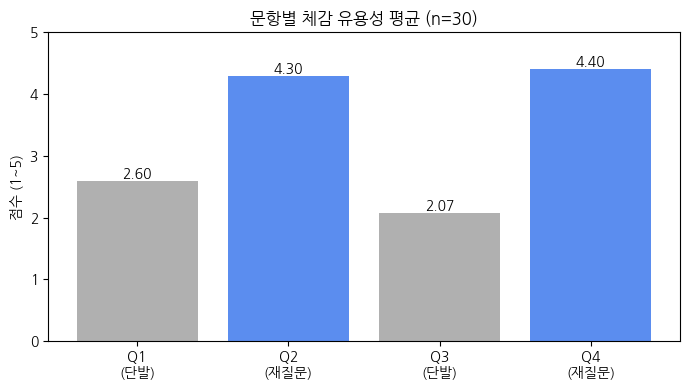

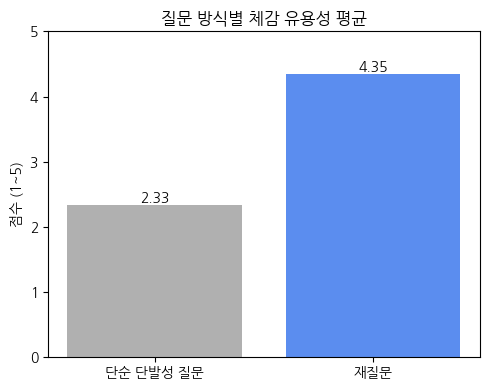

t = 14.12, p = 1.58e-14


In [2]:
!pip install -q koreanize-matplotlib

import pandas as pd
import matplotlib.pyplot as plt
import koreanize_matplotlib
from scipy import stats
from google.colab import files

# 1. 업로드 & 읽기
up = files.upload()
df = pd.read_csv(list(up.keys())[0])

# 2. "2점 (유용하지 않음)" → 2 로 변환
s = df.iloc[:, 1:5].apply(lambda c: c.str[0].astype(int))
s.columns = ['Q1', 'Q2', 'Q3', 'Q4']

# 3-1. 문항별 평균
mean = s.mean()
colors = ['#B0B0B0', '#5B8DEF', '#B0B0B0', '#5B8DEF']
plt.figure(figsize=(7, 4))
bars = plt.bar(['Q1\n(단발)', 'Q2\n(재질문)', 'Q3\n(단발)', 'Q4\n(재질문)'], mean, color=colors)
plt.bar_label(bars, fmt='%.2f')
plt.ylim(0, 5)
plt.title(f'문항별 체감 유용성 평균 (n={len(s)})')
plt.ylabel('점수 (1~5)')
plt.tight_layout()
plt.show()

# 3-2. 그룹별 평균 비교
single = (s['Q1'] + s['Q3']) / 2
refine = (s['Q2'] + s['Q4']) / 2
plt.figure(figsize=(5, 4))
bars = plt.bar(['단순 단발성 질문', '재질문'], [single.mean(), refine.mean()],
               color=['#B0B0B0', '#5B8DEF'])
plt.bar_label(bars, fmt='%.2f')
plt.ylim(0, 5)
plt.title('질문 방식별 체감 유용성 평균')
plt.ylabel('점수 (1~5)')
plt.tight_layout()
plt.show()

# 4. 대응표본 t-검정 (가설 검증용)
t, p = stats.ttest_rel(refine, single)
print(f't = {t:.2f}, p = {p:.2e}')